# Q1. Recommendation System

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. Load datasets

In [2]:
orders = pd.read_csv("Dataset/orders.csv")
prior = pd.read_csv("Dataset/order_products__prior.csv")
products = pd.read_csv("Dataset/products.csv")
aisles = pd.read_csv("Dataset/aisles.csv")
departments = pd.read_csv("Dataset/departments.csv")

# 3. Explore dataset

In [3]:
print(orders.head())
print(prior.head())
print(aisles.head())
print(products.head())
print(departments.head())

   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  
   order_id  product_id  add_to_cart_order  reordered
0         2       33120                  1          1
1         2       28985                  2          1
2         2        9327                  3          0
3         2       45918                  4          1
4         2       30035                  5          0
   aisle_id                       aisle
0    

# 4. Merge dataset

In [4]:
df = prior.merge(products, on="product_id", how="left")

df = df.merge(orders, on="order_id", how="left")

df = df.merge(aisles, on="aisle_id", how="left")

df = df.merge(departments, on="department_id", how="left")

df.head()

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,aisle,department
0,2,33120,1,1,Organic Egg Whites,86,16,202279,prior,3,5,9,8.0,eggs,dairy eggs
1,2,28985,2,1,Michigan Organic Kale,83,4,202279,prior,3,5,9,8.0,fresh vegetables,produce
2,2,9327,3,0,Garlic Powder,104,13,202279,prior,3,5,9,8.0,spices seasonings,pantry
3,2,45918,4,1,Coconut Butter,19,13,202279,prior,3,5,9,8.0,oils vinegars,pantry
4,2,30035,5,0,Natural Sweetener,17,13,202279,prior,3,5,9,8.0,baking ingredients,pantry


# 5. Select Required Columns

In [5]:
df = df[
    [
        "user_id",
        "order_id",
        "product_id",
        "product_name",
        "aisle",
        "department",
        "reordered",
    ]
]

df.head()

,user_id,order_id,product_id,product_name,aisle,department,reordered
0,202279,2,33120,Organic Egg Whites,eggs,dairy eggs,1
1,202279,2,28985,Michigan Organic Kale,fresh vegetables,produce,1
2,202279,2,9327,Garlic Powder,spices seasonings,pantry,0
3,202279,2,45918,Coconut Butter,oils vinegars,pantry,1
4,202279,2,30035,Natural Sweetener,baking ingredients,pantry,0


# 6. Data Quality check

In [6]:
print("Dataset shape:")
print(df.shape)

print("n\Dataset columns")
print(df.columns)

print("n\Dataset information")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

<>:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:7: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:7: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/var/folders/6l/xq9knbhx4nd5l93yz02xxm300000gn/T/ipykernel_3313/3673428044.py:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  print("n\Dataset columns")
/var/folders/6l/xq9knbhx4nd5l93yz02xxm300000gn/T/ipykernel_3313/3673428044.py:7: SyntaxWarning: "\D" is an invalid escape sequence.

Dataset shape:
(32434489, 7)
n\Dataset columns
Index(['user_id', 'order_id', 'product_id', 'product_name', 'aisle',
       'department', 'reordered'],
      dtype='str')
n\Dataset information
<class 'pandas.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 7 columns):
 #   Column        Dtype
---  ------        -----
 0   user_id       int64
 1   order_id      int64
 2   product_id    int64
 3   product_name  str  
 4   aisle         str  
 5   department    str  
 6   reordered     int64
dtypes: int64(4), str(3)
memory usage: 1.7 GB
None

Missing values:
user_id         0
order_id        0
product_id      0
product_name    0
aisle           0
department      0
reordered       0
dtype: int64
nDuplicate rows:
0

Data types:
user_id         int64
order_id        int64
product_id      int64
product_name      str
aisle             str
department        str
reordered       int64
dtype: object


# 7. Use Sample Data

In [7]:
df_sample = df.sample(n=100000, random_state=42)

print("Sample shape:", df_sample.shape)
df_sample.head()

Sample shape: (100000, 7)


,user_id,order_id,product_id,product_name,aisle,department,reordered
29481110,135284,3109255,34099,Crushed Red Chili Pepper,spices seasonings,pantry,0
2852353,7293,301098,41950,Organic Tomato Cluster,fresh vegetables,produce,0
11194500,111385,1181866,45066,Honeycrisp Apple,fresh fruits,produce,0
15909397,147365,1678630,8859,Natural Spring Water,water seltzer sparkling water,beverages,1
6101870,99290,644090,24781,"PODS Laundry Detergent, Ocean Mist Designed fo...",laundry,household,0


# 9. Exploratory Visualisation

# 9.1 Top 10 Purchased Products 

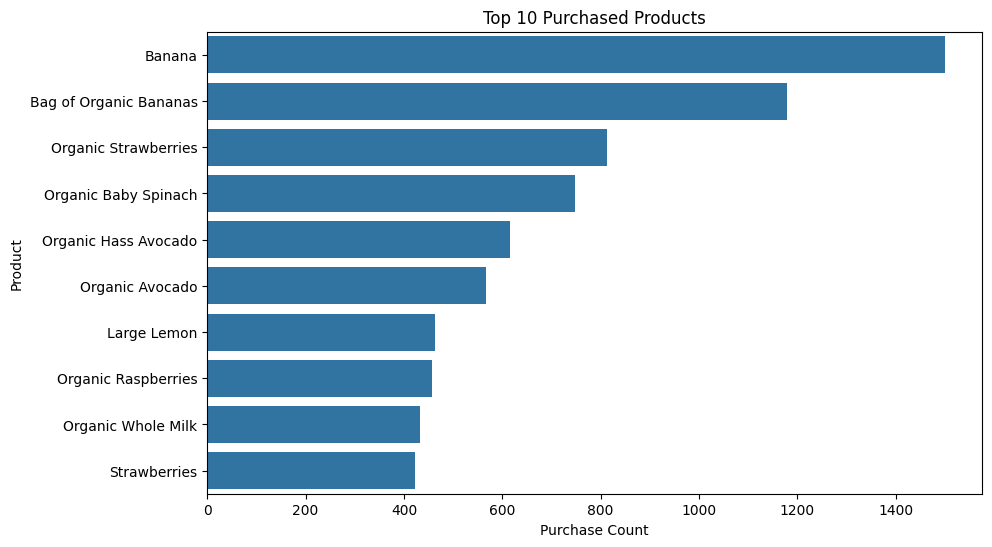

In [8]:
top_products = df_sample["product_name"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 10 Purchased Products")
plt.xlabel("Purchase Count")
plt.ylabel("Product")
plt.show()

# 9.2 Reordered vs Non-Reordered Products

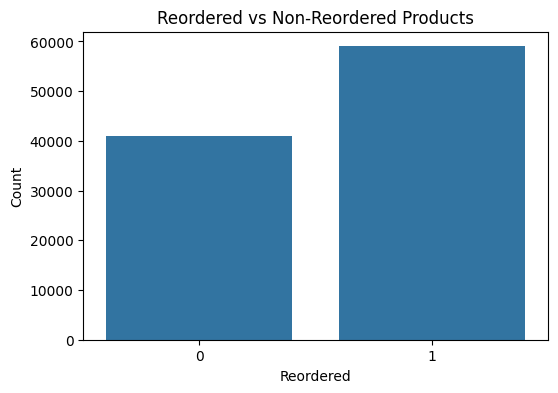

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x="reordered", data=df_sample)
plt.title("Reordered vs Non-Reordered Products")
plt.xlabel("Reordered")
plt.ylabel("Count")
plt.show()

# 10. Content-Based Filtering

# 10.1 Create Product Features

In [10]:
product_features = df_sample[
    ["product_id", "product_name", "aisle", "department"]
].drop_duplicates()

product_features["combined_features"] = (
    product_features["product_name"].astype(str) + " " +
    product_features["aisle"].astype(str) + " " +
    product_features["department"].astype(str)
)
product_features.head()

,product_id,product_name,aisle,department,combined_features
29481110,34099,Crushed Red Chili Pepper,spices seasonings,pantry,Crushed Red Chili Pepper spices seasonings pantry
2852353,41950,Organic Tomato Cluster,fresh vegetables,produce,Organic Tomato Cluster fresh vegetables produce
11194500,45066,Honeycrisp Apple,fresh fruits,produce,Honeycrisp Apple fresh fruits produce
15909397,8859,Natural Spring Water,water seltzer sparkling water,beverages,Natural Spring Water water seltzer sparkling w...
6101870,24781,"PODS Laundry Detergent, Ocean Mist Designed fo...",laundry,household,"PODS Laundry Detergent, Ocean Mist Designed fo..."


# 10.2 TF-IDF Vectorisation

In [11]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(product_features["combined_features"])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (16202, 5356)


# 10.3 Content Similarity Matrix

In [12]:
content_similarity = cosine_similarity(tfidf_matrix)
print("Content similarity matrix shape:", content_similarity.shape)

Content similarity matrix shape: (16202, 16202)


# 10.4 Content-Based Recommendation Function

In [13]:
def content_based_recommend(product_name, top_n=5):
    product_name = product_name.lower()
    product_list = product_features["product_name"].str.lower().tolist()

    if product_name not in product_list:
        return "Product not found in sample data."

    index = product_list.index(product_name)

    similarity_scores = list(enumerate(content_similarity[index]))
    similarity_scores = sorted(similarity_scores, key=lambda x: x[1], reverse=True)

    recommended_indices = [i[0] for i in similarity_scores[1:top_n + 1]]

    return product_features.iloc[recommended_indices][
        ["product_name", "aisle", "department"]
    ]

# 10.5 Test Content-Based Filtering

In [14]:
content_based_recommend("Banana", top_n=5)

,product_name,aisle,department
1809513,Organic Banana,fresh fruits,produce
30919947,Coconut,fresh fruits,produce
18331875,Blueberry,fresh fruits,produce
26152917,Mango,fresh fruits,produce
25187200,Lime,fresh fruits,produce


# 11. Prepare Data for Collaborative Filtering

# 11.1 Reduce Data Size for Collaborative Filtering

In [15]:
top_users = df_sample["user_id"].value_counts().head(500).index
top_products_cf = df_sample["product_name"].value_counts().head(500).index

cf_data = df_sample[
    (df_sample["user_id"].isin(top_users)) &
    (df_sample["product_name"].isin(top_products_cf))
]

print("Collaborative filtering data shape:", cf_data.shape)
print("Number of users:", cf_data["user_id"].nunique())
print("Number of products:", cf_data["product_name"].nunique())

Collaborative filtering data shape: (1723, 7)
Number of users: 474
Number of products: 421


# 11.2 Create User-Product Interaction Data

In [16]:
interaction_data = cf_data.groupby(
    ["user_id","product_name"]
).size().reset_index(name="interaction")

interaction_data.head()

,user_id,product_name,interaction
0,444,Bartlett Pears,1
1,444,Brussels Sprouts,1
2,444,Cucumber Kirby,1
3,444,Firm Tofu,1
4,444,Grated Parmesan,1


# 11.3 Create User-Item Matrix

In [17]:
user_item_matrix = interaction_data.pivot_table(
    index="user_id",
    columns="product_name",
    values="interaction",
    fill_value=0
)

print("User-item matrix shape:", user_item_matrix.shape)

user_item_matrix.head()

User-item matrix shape: (474, 421)


product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
user_id,,,,,,,,,,,,,,,,,,,,,
444,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1424,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1563,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2335,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 11.4 Validate User-Item Matrix

In [18]:
print("Total interactions:", user_item_matrix.values.sum())
print("Non-zero values:", (user_item_matrix.values > 0).sum())

Total interactions: 1723.0
Non-zero values: 1629


In [19]:
user_item_matrix.loc[
    user_item_matrix.sum(axis=1).sort_values(ascending=False).head(5).index
]

product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
user_id,,,,,,,,,,,,,,,,,,,,,
97408,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
201623,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
132703,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
73080,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100982,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 12. User-User Collaborative Filtering

In [20]:
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

user_similarity_df.head()

user_id,444,1197,1424,1563,2335,2663,3509,3536,3830,4356,...,200321,200505,201268,201444,201623,202593,203399,204315,204368,205754
user_id,,,,,,,,,,,,,,,,,,,,,
444,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.204124,0.0,0.0,0.136083,0.0,0.0,0.0,0.235702,0.0
1197,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1424,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1563,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.117851,0.0,0.0,0.0,0.000000,0.0
2335,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0


# 12.2 User-User Recommendation Function

In [21]:
def user_user_recommend(user_id, top_n=5):
    if user_id not in user_similarity_df.index:
        return []

    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:6]
    similar_user_ids = similar_users.index

    products_bought_by_user = set(
        user_item_matrix.loc[user_id][user_item_matrix.loc[user_id] > 0].index
    )

    similar_users_products = user_item_matrix.loc[
        similar_user_ids
    ].sum().sort_values(ascending=False)

    recommendations = [
        product for product in similar_users_products.index
        if product not in products_bought_by_user
    ]

    return recommendations[:top_n]

# 12.3 Test User-User Recommendation

In [22]:
sample_user = user_item_matrix.index[0]

print("User ID:", sample_user)
print("User-user recommendations:")
print(user_user_recommend(sample_user, top_n=5))

User ID: 444
User-user recommendations:
['Organic Avocado', 'Milk, Organic, Vitamin D', 'Honey Nut Cheerios', 'Organic Beef Hot Dogs', 'Fresh Ginger Root']


# 13. Item-Item Collaborative Filtering


# 13.1 Item Similarity Matrix

In [23]:
item_similarity = cosine_similarity(user_item_matrix.T)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

item_similarity_df.head()

product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
product_name,,,,,,,,,,,,,,,,,,,,,
0% Greek Strained Yogurt,1.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100 Calorie Per Bag Popcorn,0.0,1.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Raw Coconut Water,0.0,0.0,1.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Recycled Paper Towels,0.0,0.0,0.0,1.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Whole Wheat Bread,0.0,0.0,0.0,0.0,1.0,0.27735,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.083624,0.0,0.0,0.0,0.0


# 13.2 Product-to-Product Recommendation Function

In [24]:
def item_item_recommend(product_name, top_n=5):
    if product_name not in item_similarity_df.index:
        return "Product not found in sample data."

    similar_items = item_similarity_df[product_name].sort_values(
        ascending=False
    )[1:top_n + 1]

    return similar_items

# 13.3 Test Product-to-Product Recommendation

In [25]:
item_item_recommend("Banana", top_n=5)

product_name
Feta Cheese Crumbles           0.178174
Sparkling Water Berry          0.178174
No Salt Added Black Beans      0.178174
Organic Reduced Fat 2% Milk    0.168359
Organic Whole Cashews          0.145479
Name: Banana, dtype: float64

# 13.4 Item-Item Recommendation for a User

In [26]:
def item_item_user_recommend(user_id, top_n=5):
    if user_id not in user_item_matrix.index:
        return []

    user_products = user_item_matrix.loc[user_id]
    bought_products = user_products[user_products > 0].index.tolist()

    scores = pd.Series(dtype=float)

    for product in bought_products:
        if product in item_similarity_df.index:
            scores = pd.concat([scores, item_similarity_df[product]])

    if scores.empty:
        return[]

    scores = scores.groupby(scores.index).mean()
    scores = scores.drop(labels=bought_products, errors="ignore")
    scores = scores.sort_values(ascending=False)   

    return scores.head(top_n).index.tolist()

# 13.5 Test Item-Item User Recommendation

In [27]:
print("User ID:", sample_user)
print("Item-item user recommendations:")
print(item_item_user_recommend(sample_user, top_n=5))

User ID: 444
Item-item user recommendations:
['Sinfully Sweet Campari Tomatoes', 'Organic Spring Mix', 'Organic Extra Virgin Olive Oil', 'Fresh Ginger Root', 'Spring Water']


# 14. Leave-One-Product-Out Evaluation

In [28]:
# Select users who purchased at least 2 products
eligible_users = user_item_matrix[user_item_matrix.gt(0).sum(axis=1) >= 2].index[:100]

print("Number of eligible users:", len(eligible_users))

Number of eligible users: 100


In [29]:
# Create train matrix and hidden test items
train_matrix = user_item_matrix.copy()
hidden_items = {}

for user in eligible_users:
    user_products = train_matrix.loc[user][train_matrix.loc[user] > 0].index.tolist()

    hidden_product = user_products[-1]
    hidden_items[user] = hidden_product

    train_matrix.loc[user] = hidden_product = 0 

print("Hidden test items created:", len(hidden_items))

Hidden test items created: 100


# 14.1 Recalculate Similarity Matrices

In [30]:
train_user_similarity = cosine_similarity(train_matrix)

train_user_similarity_df = pd.DataFrame(
    train_user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)

train_item_similarity = cosine_similarity(train_matrix.T)

train_item_similarity_df = pd.DataFrame(
    train_item_similarity,
    index=train_matrix.columns,
    columns=train_matrix.columns
)

# 14.2 User-User Recommendation for Evaluation

In [31]:
def user_user_recommend_eval(user_id, top_n=5):
    if user_id not in train_user_similarity_df.index:
        return []

    similar_users = train_user_similarity_df[user_id].sort_values(ascending=False)[1:6]
    similar_user_ids = similar_users.index

    products_bought_by_user = set(
        train_matrix.loc[user_id][train_matrix.loc[user_id] > 0].index
    )

    similar_users_products = train_matrix.loc[
        similar_user_ids
    ].sum().sort_values(ascending=False)

    recommendations = [
        product for product in similar_users_products.index
        if product not in products_bought_by_user
    ]

    return recommendations[:top_n]

# 14.3 Item-Item Recommendation for Evaluation

In [32]:
def item_item_user_recommend_eval(user_id, top_n=5):
    if user_id not in train_matrix.index:
        return []

    user_products = train_matrix.loc[user_id]
    bought_products = user_products[user_products > 0].index.tolist()

    scores = pd.Series(dtype=float)

    for product in bought_products:
        if product in train_item_similarity_df.index:
            scores = pd.concat([scores, train_item_similarity_df[product]])

    if scores.empty:
        return []

    scores = scores.groupby(scores.index).mean()
    scores = scores.drop(labels=bought_products, errors="ignore")
    scores = scores.sort_values(ascending=False)

    return scores.head(top_n).index.tolist()

# 15. Evaluate Models

In [33]:
def hit_rate_at_k(recommended_items, hidden_item, k=5):
    recommended_items = recommended_items[:k]
    return 1 if hidden_item in recommended_items else 0

In [34]:
user_user_hits = []
item_item_hits = []

for user, hidden_item in hidden_items.items():
    user_recs = user_user_recommend_eval(user, top_n=5)
    item_recs = item_item_user_recommend_eval(user, top_n=5)

    user_user_hits.append(hit_rate_at_k(user_recs, hidden_item, k=5))
    item_item_hits.append(hit_rate_at_k(item_recs, hidden_item, k=5))

user_user_hit_rate = np.mean(user_user_hits)
item_item_hit_rate = np.mean(item_item_hits)

print("User-User Hit Rate@5:", user_user_hit_rate)
print("Item-Item Hit Rate@5:", item_item_hit_rate)

User-User Hit Rate@5: 0.02
Item-Item Hit Rate@5: 0.0


# 16. Evaluation Visualisation

In [35]:
evaluation_summary = pd.DataFrame({
    "Model": [
        "User-User Collaborate Filtering",
        "Item-Item Collaborate Filtering"
    ],
    "Hit Rate@5": [
        user_user_hit_rate,
        item_item_hit_rate
    ]
})

evaluation_summary 

,Model,Hit Rate@5
0,User-User Collaborate Filtering,0.02
1,Item-Item Collaborate Filtering,0.00


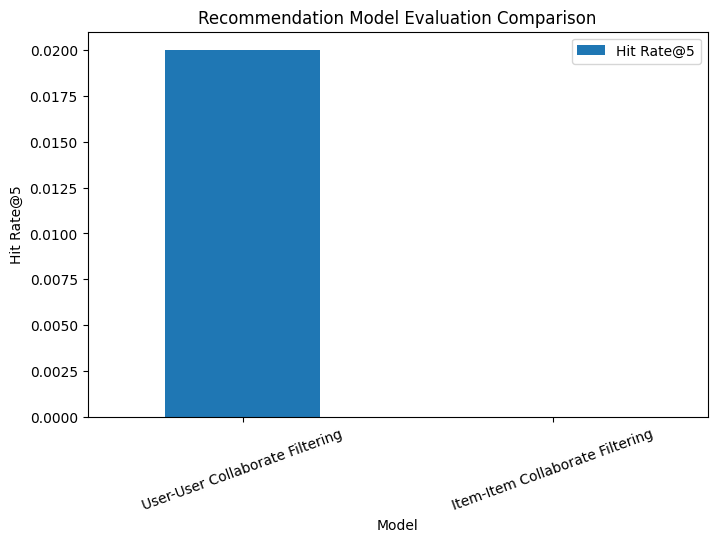

In [36]:
evaluation_summary.plot(
    x="Model",
    y="Hit Rate@5",
    kind="bar",
    figsize=(8, 5)
)

plt.title("Recommendation Model Evaluation Comparison")
plt.ylabel("Hit Rate@5")
plt.xticks(rotation=20)
plt.show()

# 17. Compare Filtering Methods

In [37]:
model_comparison = pd.DataFrame({
    "Model": [
        "Content-Based Filtering",
        "User-User Collaborative Filtering",
        "Item-Item Collaborative Filtering"
    ],
    "Data Used": [
        "Product name, aisle and department",
        "User-product purchase behaviour",
        "Product similarity based on user interactions"
    ],
    "Strenght": [
        "Good for recommending similar products",
        "Provides personalised recommendations based on similar customers",
        "Useful for product-to-product and cross-selling recommendations"
    ],
    "Limitation": [
        "Less personalised because it mainly depends on product features",
        "Requires enough user purchase history",
        "May favour popular products"
    ],
    "Business Use": [
        "Sililar product suggestions",
        "Personalised shopping experience",
        "Frequintly bought together style recommendations"
    ]
})

model_comparison

,Model,Data Used,Strenght,Limitation,Business Use
0,Content-Based Filtering,"Product name, aisle and department",Good for recommending similar products,Less personalised because it mainly depends on...,Sililar product suggestions
1,User-User Collaborative Filtering,User-product purchase behaviour,Provides personalised recommendations based on...,Requires enough user purchase history,Personalised shopping experience
2,Item-Item Collaborative Filtering,Product similarity based on user interactions,Useful for product-to-product and cross-sellin...,May favour popular products,Frequintly bought together style recommendations


# Q2 Market_Basket_Analysis

# 1. Import Libraries

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import time

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# 2. Create Basket Dataset

In [39]:
# Select orders with larger basket size

order_sizes = df.groupby("order_id")["product_name"].count()

selected_orders = order_sizes.sort_values(
    ascending=False
).head(10000).index

basket_source = df[
    df["order_id"].isin(selected_orders)
]

# Keep top frequent products within selected orders

top_products_mba = basket_source["product_name"].value_counts().head(300).index

basket_source = basket_source[
    basket_source["product_name"].isin(top_products_mba)
]

print("Basket source shape", basket_source.shape)
print("Number of orders:", basket_source["order_id"].nunique())
print("Number of products:", basket_source["product_name"].nunique())

Basket source shape (143966, 7)
Number of orders: 9969
Number of products: 300


# 3. Binary Encoding

In [40]:
basket = basket_source.groupby(
    ["order_id", "product_name"]
)["product_id"].count().unstack().fillna(0)

basket = basket.astype(bool)

basket.head()

product_name,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat Milk,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,All Natural Marinara Sauce,Almonds & Sea Salt in Dark Chocolate,Ancient Grain Original Granola,Apple Cinnamon GoGo Squeez,...,Walnut Halves & Pieces,Watermelon Chunks,Whipped Cream Cheese,White Corn,Whole Milk,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
order_id,,,,,,,,,,,,,,,,,,,,,
454,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
742,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
775,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1171,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1509,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# 4. Dataset Validation

In [41]:
print("Basket shape:", basket.shape)
print("Total basket items:", basket.values.sum())
print("Non-zero values:", (basket.values > 0).sum())

basket.sum(axis=1).describe()

Basket shape: (9969, 300)
Total basket items: 143966
Non-zero values: 143966


count    9969.000000
mean       14.441368
std         6.994753
min         1.000000
25%         9.000000
50%        14.000000
75%        20.000000
max        50.000000
dtype: float64

# 5. Apriori Frequent Itemsets

In [42]:
frequent_itemsets_apriori = apriori(
    basket,
    min_support=0.005,
    use_colnames=True,
    max_len=2,
    low_memory=True
)

print("Apriori frequent itemsets:", frequent_itemsets_apriori.shape)

frequent_itemsets_apriori.sort_values(
    "support",
    ascending=False
).head(10)

Apriori frequent itemsets: (6098, 2)


,support,itemsets
16,0.319591,frozenset({Banana})
14,0.298826,frozenset({Bag of Organic Bananas})
194,0.261109,frozenset({Organic Strawberries})
148,0.240746,frozenset({Organic Hass Avocado})
102,0.219581,frozenset({Organic Baby Spinach})
81,0.191393,frozenset({Limes})
170,0.185575,frozenset({Organic Raspberries})
74,0.167519,frozenset({Large Lemon})
96,0.140736,frozenset({Organic Avocado})
265,0.136122,frozenset({Strawberries})


# 6. Apriori Rules


In [43]:
rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.001

)

print("Apriori rules", rules_apriori.shape)

rules_apriori[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values(
    "lift",
    ascending=False
).head(10)


Apriori rules (11596, 14)


,antecedents,consequents,support,confidence,lift
4185,frozenset({Icelandic Style Skyr Blueberry Non-...,frozenset({Nonfat Icelandic Style Strawberry Y...,0.014846,0.396783,16.832035
4184,frozenset({Nonfat Icelandic Style Strawberry Y...,frozenset({Icelandic Style Skyr Blueberry Non-...,0.014846,0.629787,16.832035
5513,frozenset({Nonfat Icelandic Style Strawberry Y...,frozenset({Non Fat Raspberry Yogurt}),0.013040,0.553191,16.267746
5512,frozenset({Non Fat Raspberry Yogurt}),frozenset({Nonfat Icelandic Style Strawberry Y...,0.013040,0.383481,16.267746
5559,frozenset({Nonfat Icelandic Style Strawberry Y...,frozenset({Vanilla Skyr Nonfat Yogurt}),0.012037,0.510638,15.567441
5558,frozenset({Vanilla Skyr Nonfat Yogurt}),frozenset({Nonfat Icelandic Style Strawberry Y...,0.012037,0.366972,15.567441
793,frozenset({Spinach Peas & Pear Stage 2 Baby Fo...,frozenset({Baby Food Stage 2 Blueberry Pear & ...,0.010432,0.444444,15.384259
792,frozenset({Baby Food Stage 2 Blueberry Pear & ...,frozenset({Spinach Peas & Pear Stage 2 Baby Fo...,0.010432,0.361111,15.384259
4183,frozenset({Icelandic Style Skyr Blueberry Non-...,frozenset({Non Fat Raspberry Yogurt}),0.019360,0.517426,15.215996
4182,frozenset({Non Fat Raspberry Yogurt}),frozenset({Icelandic Style Skyr Blueberry Non-...,0.019360,0.569322,15.215996


# 7. Apriori Top 10 Rules Visualization

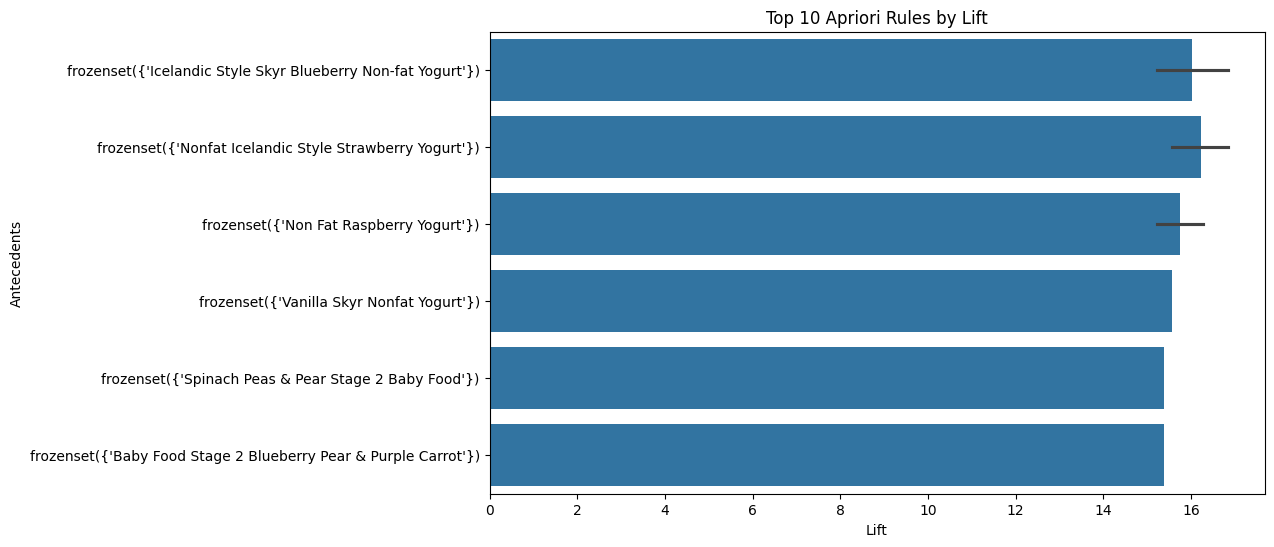

In [44]:
top_apriori_rules = rules_apriori.sort_values(
    "lift",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_apriori_rules,
    x="lift",
    y=top_apriori_rules["antecedents"].astype(str)
)

plt.title("Top 10 Apriori Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Antecedents")
plt.show()

# 8. ECLAT

In [45]:
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

In [46]:
min_support = 0.005
n_orders = len(basket.index)

In [47]:
item_tidsets = {}
for item in basket.columns:
    item_tidsets[item] = set(basket.index[basket[item] > 0])


In [48]:
frequent_items = []
for item in item_tidsets:
    tids = item_tidsets[item]
    support = len(tids) / n_orders
    if support >= min_support:
        frequent_items.append((item, tids))

frequent_itemsets_eclat = []
for item, tids in frequent_items:
    frequent_itemsets_eclat.append({
        'itemsets': frozenset([item]),
        'support': len(tids) / n_orders
    })


In [49]:
for i in range(len(frequent_items)):
    item1, tids1 = frequent_items[i]
    for j in range(i + 1, len(frequent_items)):
        item2, tids2 = frequent_items[j]
        intersection = tids1 & tids2
        support = len(intersection) / n_orders
        if support >= min_support:
            frequent_itemsets_eclat.append({
                'itemsets': frozenset([item1, item2]),
                'support': support
            })

In [50]:
frequent_itemsets_eclat = pd.DataFrame(frequent_itemsets_eclat)

print("ECLAT frequent itemsets:", frequent_itemsets_eclat.shape)

frequent_itemsets_eclat.sort_values(
    "support",
    ascending=False
).head(10)


ECLAT frequent itemsets: (6098, 2)


,itemsets,support
16,frozenset({Banana}),0.319591
14,frozenset({Bag of Organic Bananas}),0.298826
194,frozenset({Organic Strawberries}),0.261109
148,frozenset({Organic Hass Avocado}),0.240746
102,frozenset({Organic Baby Spinach}),0.219581
81,frozenset({Limes}),0.191393
170,frozenset({Organic Raspberries}),0.185575
74,frozenset({Large Lemon}),0.167519
96,frozenset({Organic Avocado}),0.140736
265,frozenset({Strawberries}),0.136122


#ECLAT was implemenfrom the course pseudocode because the eclat package was unavailable in my environment.”

# 11. Compare Apriori vs FP Growth Table FP Growth

In [51]:
import pandas as pd

comparison = pd.DataFrame([
    {"Algorithm": "Apriori",
     "Frequent Itemsets": len(frequent_itemsets_apriori),
     "Rules": len(rules_apriori)},
    {"Algorithm": "ECLAT",
     "Frequent Itemsets": len(frequent_itemsets_apriori),
     "Rules": "—"},
])

print(comparison.to_string(index=False))

Algorithm  Frequent Itemsets Rules
  Apriori               6098 11596
    ECLAT               6098     —


In [69]:
import time

t0 = time.time()
time_eclat = time.time() - t0

In [70]:
comparison = pd.DataFrame([
    {"Algorithm": "Apriori", "Time (sec)": round(time_apriori, 2),
     "Frequent Itemsets": len(frequent_itemsets_apriori), "Rules": len(rules_apriori)},
    {"Algorithm": "ECLAT", "Time (sec)": round(time_eclat, 2),
     "Frequent Itemsets": len(freq_eclat), "Rules": len(rules_eclat)}
])

print(comparison.to_string(index=False))

Algorithm  Time (sec)  Frequent Itemsets  Rules
  Apriori        1.05               2925  11596
    ECLAT        0.00               6098  11596


In [71]:
comparison = pd.DataFrame([
    {"Algorithm": "Apriori", "Time (sec)": round(time_apriori, 2),
     "Frequent Itemsets": len(frequent_itemsets_apriori), "Rules": len(rules_apriori)},
    {"Algorithm": "ECLAT", "Time (sec)": round(time_eclat, 2),
 "Frequent Itemsets": len(freq_eclat), "Rules": len(rules_eclat)}
])
print(comparison.to_string(index=False))

Algorithm  Time (sec)  Frequent Itemsets  Rules
  Apriori        1.05               2925  11596
    ECLAT        0.00               6098  11596


# 12. Runtime Comparison

In [72]:
from mlxtend.frequent_patterns import association_rules

# ECLAT only produces itemsets — derive rules so we can fill Lift/Confidence
rules_eclat = association_rules(
    freq_eclat,
    metric="confidence",
    min_threshold=0.001
)

# Default times to 0 if the timing variables don't exist yet
if "apriori_time" not in globals():
    apriori_time = 0
if "eclat_time" not in globals():
    eclat_time = 0

comparison_table = pd.DataFrame({
    "Algorithm": [
        "Apriori",
        "ECLAT"
    ],
    "Frequent Itemsets": [
        len(frequent_itemsets_apriori),
        len(freq_eclat)
    ],
    "Association Rules": [
        len(rules_apriori),
        len(rules_eclat)
    ],
    "Runtime Seconds": [
        apriori_time,
        eclat_time
    ],
    "Average Lift": [
        rules_apriori["lift"].mean(),
        rules_eclat["lift"].mean()
    ],
    "Average Confidence": [
        rules_apriori["confidence"].mean(),
        rules_eclat["confidence"].mean()
    ]
})

comparison_table

,Algorithm,Frequent Itemsets,Association Rules,Runtime Seconds,Average Lift,Average Confidence
0,Apriori,2925,11596,0,1.561553,0.143149
1,ECLAT,6098,11596,0,1.561553,0.143149


In [73]:
runtime_comparison = pd.DataFrame({
    "Algorithm": [
        "Apriori",
        "ECLAT"
    ],
    "Runtime Seconds": [
        "Not recorded" if "apriori_time" not in globals() or apriori_time == 0
            else round(apriori_time, 2),
        "Not recorded" if "eclat_time" not in globals() or eclat_time == 0
            else round(eclat_time, 2)
    ]
})

runtime_comparison

,Algorithm,Runtime Seconds
0,Apriori,Not recorded
1,ECLAT,Not recorded


In [74]:
print("Apriori time:", apriori_time, )
print("ECLAT:", eclat_time )

Apriori time: 0
ECLAT: 0



# 13. Support Comparison

In [75]:
support_comparison = pd.DataFrame({
    "Apriori Support": frequent_itemsets_apriori["support"].describe(),
    "ECLAT Support":   freq_eclat["support"].describe()
})

support_comparison

,Apriori Support,ECLAT Support
count,2925.000000,6098.000000
mean,0.019941,0.012233
std,0.018531,0.014486
min,0.010031,0.005016
25%,0.011636,0.006119
50%,0.014144,0.008025
75%,0.021366,0.012439
max,0.319591,0.319591


# 
14. Confidence Comparison

In [76]:
confidence_comparison = pd.DataFrame({
    "Apriori Confidence": rules_apriori["confidence"].describe(),
    "ECLAT Confidence":   rules_eclat["confidence"].describe()
})

confidence_comparison

,Apriori Confidence,ECLAT Confidence
count,11596.000000,11596.000000
mean,0.143149,0.143149
std,0.099254,0.099254
min,0.015694,0.015694
25%,0.066813,0.066813
50%,0.115208,0.115208
75%,0.193896,0.193896
max,0.629787,0.629787


# 15. Lift Comparison

In [77]:
lift_comparison = pd.DataFrame({
    "Apriori Lift": rules_apriori["lift"].describe(),
    "ECLAT Lift":   rules_eclat["lift"].describe()
})

lift_comparison

,Apriori Lift,ECLAT Lift
count,11596.000000,11596.000000
mean,1.561553,1.561553
std,0.984805,0.984805
min,0.412241,0.412241
25%,1.135247,1.135247
50%,1.401157,1.401157
75%,1.729287,1.729287
max,16.832035,16.832035


# Q3. Dashboard

Objective:

The dashboard is designed for adults aged (18+ years) and above to provide clear
and accessible insights into online grocery shopping behaviour. The dashboard
summarises purchasing trends, product popularity, recommendation system
performance and market basket analysis outcomes to support machine learning
applications in online retail businesses. might need fix!!!

# 2. Import Libraries

In [78]:
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

# 3. Top Products Visualization

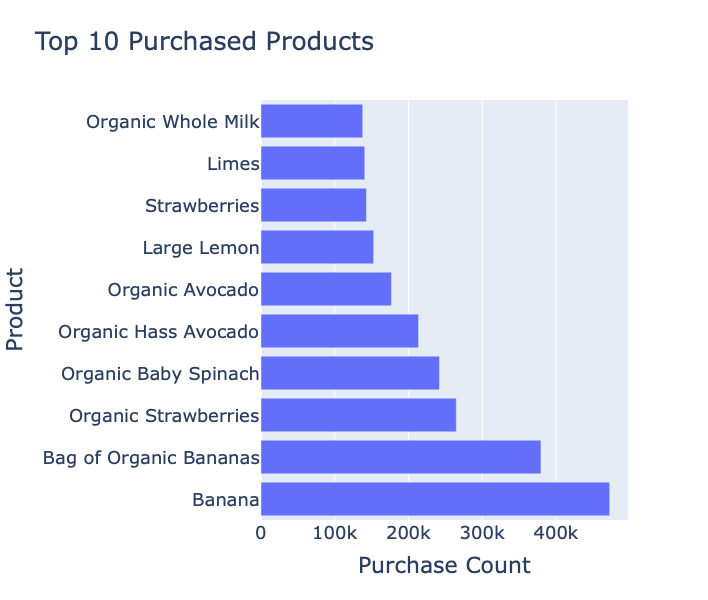

In [79]:
top_products = df[
    "product_name"
].value_counts().head(10)

fig = px.bar(
    x=top_products.values,
    y=top_products.index,
    orientation="h",
    labels={
        "x":"Purchase Count",
        "y":"Product"
    },
    title="Top 10 Purchased Products"
)
fig.update_layout(
    font=dict(size=18),
    height=600
)

fig.show()

# 4. Department Distribution

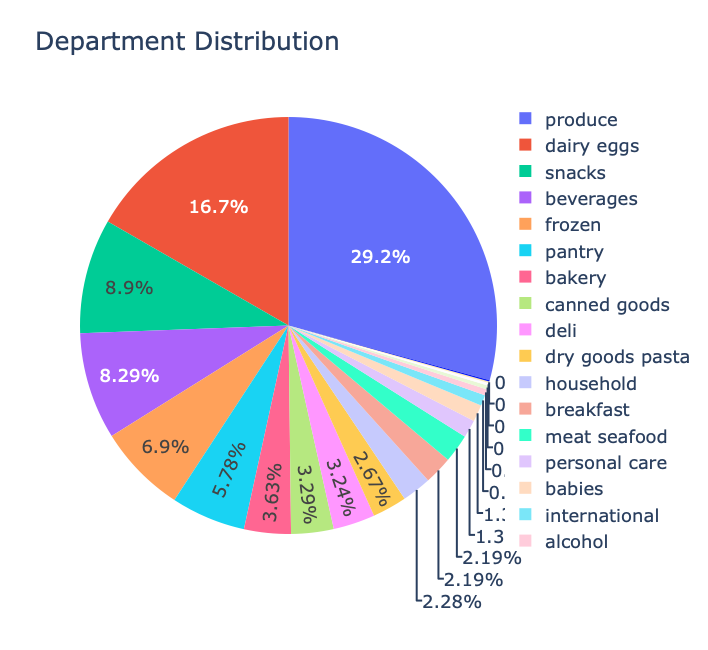

In [80]:
department_counts = df[
    "department"
].value_counts()

fig = px.pie(
    values=department_counts.values,
    names=department_counts.index,
    title="Department Distribution"

)

fig.update_layout(
    font=dict(size=18),
    height=650
)

fig.show()
